# Analysis and Visualization of Social Media Data

This notebook analyzes Reddit social-media comments using DuckDB, pandas, text processing, graph visualization, and statistical plots.

**Generated files:** all charts, the comment-tree visualization, and the sentiment/importance CSV are saved in `outputs/figures/`.


In [1]:
import json
import duckdb
import graphviz
import re
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from graphviz import Digraph
import seaborn as sns
import pyarrow
import jupyter
import openpyxl
import textwrap
import os
import requests
from urllib.request import Request, urlopen
import shutil
from IPython.display import HTML, Javascript, display
from IPython.display import display
from pathlib import Path
from nltk.tokenize import TreebankWordTokenizer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from matplotlib.ticker import FuncFormatter

In [2]:
OUTPUT_DIR = Path.cwd() / "outputs" / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output directory:", OUTPUT_DIR.resolve())
print("Directory exists:", OUTPUT_DIR.exists())

Output directory: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures
Directory exists: True


In [3]:
FILE_PATH = Path("data/processed/data/programming-00000-of-00007-682384b233d9a62b.csv")
if not FILE_PATH.is_file():
    raise FileNotFoundError(
        f"CSV dataset not found: {FILE_PATH.resolve()}\n"
        "Run scripts/csv_to_csv.py first, or update FILE_PATH."
    )
CSV_PATH = FILE_PATH.resolve().as_posix().replace("'", "''")
CSV_SOURCE = f"read_csv_auto('{CSV_PATH}', header = true, sample_size = -1)"
query = f"""
    SELECT *
    FROM {CSV_SOURCE}
    LIMIT 5
"""
df_preview = duckdb.sql(query).df()
display(df_preview)

,archived,author,author_fullname,body,comment_type,controversiality,created_utc,edited,gilded,id,...,locked,name,parent_id,permalink,retrieved_on,score,subreddit_id,subreddit_name_prefixed,subreddit_type,total_awards_received
0,False,[deleted],None,[deleted],None,0,1543622641,False,0,eatmcpf,...,<NA>,None,t1_easikql,/r/programming/comments/a1rp4s/why_is_2_i_i_fa...,1546258391,31,t5_2fwo,r/programming,public,<NA>
1,False,13steinj,t2_i487l,When most people say what he did they are refe...,None,0,1544758550,False,0,ebqu3hi,...,<NA>,None,t1_ebqm24t,/r/programming/comments/a5gx0c/how_reddit_rank...,1547582038,1,t5_2fwo,r/programming,public,<NA>
2,False,noir_lord,t2_3655m,"To err is human, to really fuck up you need a ...",None,0,1543622647,False,0,eatmcxp,...,<NA>,None,t1_eatkolb,/r/programming/comments/a1t38z/a_collection_of...,1546258394,2,t5_2fwo,r/programming,public,<NA>
3,False,ArrrGaming,t2_c3hig,Why would I need to search the menu for my fav...,None,0,1544758569,False,0,ebqu4ca,...,<NA>,None,t3_a5sg9k,/r/programming/comments/a5sg9k/how_unix_progra...,1547582048,1,t5_2fwo,r/programming,public,<NA>
4,False,stevegrossman83b,t2_1lm5r842,You can always calculate and cache the inverse...,None,0,1543622776,False,0,eatmhv4,...,<NA>,None,t1_eatfge5,/r/programming/comments/a1sbwp/not_all_cpu_ope...,1546258455,2,t5_2fwo,r/programming,public,<NA>


## 1. Data Loading and DuckDB Setup


In [4]:
print(f"---DuckDB View---")
duckdb.sql(f"""
    CREATE OR REPLACE VIEW reddit_comments AS
    SELECT *
    FROM {CSV_SOURCE}
""")
print("Reusable view created: reddit_comments")


---DuckDB View---
Reusable view created: reddit_comments


In [5]:
query = f"""
    SELECT id, parent_id, link_id
    FROM '{FILE_PATH}'
    WHERE parent_id IS NOT NULL
    LIMIT 5
"""
format_check = duckdb.sql(query).df()
display(format_check)

,id,parent_id,link_id
0,eatmcpf,t1_easikql,t3_a1rp4s
1,ebqu3hi,t1_ebqm24t,t3_a5gx0c
2,eatmcxp,t1_eatkolb,t3_a1t38z
3,ebqu4ca,t3_a5sg9k,t3_a5sg9k
4,eatmhv4,t1_eatfge5,t3_a1sbwp


In [6]:
print("---Dataframe Shape---")
print(f"Rows: {df_preview.shape[0]}, Columns: {df_preview.shape[1]}\n")

print("---Column Names and Data Types---")
print(f"{df_preview.dtypes}\n")

print("---Total Dataset---")
total_rows = (
    duckdb.sql(f"SELECT COUNT(*) AS total FROM reddit_comments")
    .fetchall()[0][0]
)
print(f"Full csv file contains: {total_rows:,} rows.\n")

---Dataframe Shape---
Rows: 5, Columns: 21

---Column Names and Data Types---
archived                      bool
author                         str
author_fullname                str
body                           str
comment_type                object
controversiality             int64
created_utc                  int64
edited                         str
gilded                       int64
id                             str
link_id                        str
locked                     boolean
name                        object
parent_id                      str
permalink                      str
retrieved_on                 int64
score                        int64
subreddit_id                   str
subreddit_name_prefixed        str
subreddit_type                 str
total_awards_received        Int64
dtype: object

---Total Dataset---
Full csv file contains: 1,071,907 rows.



## 2. Selecting and Inspecting a Discussion Thread


In [7]:
id_check = duckdb.sql(f"""
    SELECT id, parent_id, link_id, author
    FROM reddit_comments
    WHERE parent_id IS NOT NULL AND parent_id != 'None'
    LIMIT 10
""").df()
display(id_check)
post_query = f"""
    SELECT
        link_id,
        COUNT(*) AS num_comments
    FROM reddit_comments
    WHERE body IS NOT NULL
        AND author != '[deleted]'
    GROUP BY link_id
    HAVING COUNT(*) BETWEEN 20 AND 40
    LIMIT 5
"""
post_candidates = duckdb.sql(post_query).df()
display(post_candidates)

,id,parent_id,link_id,author
0,eatmcpf,t1_easikql,t3_a1rp4s,[deleted]
1,ebqu3hi,t1_ebqm24t,t3_a5gx0c,13steinj
2,eatmcxp,t1_eatkolb,t3_a1t38z,noir_lord
3,ebqu4ca,t3_a5sg9k,t3_a5sg9k,ArrrGaming
4,eatmhv4,t1_eatfge5,t3_a1sbwp,stevegrossman83b
5,ebqu9pz,t1_ebph33i,t3_a5mk9z,iBzOtaku
6,eatmk3e,t3_a1xjwr,t3_a1xjwr,claytonkb
7,ebqujy2,t1_ebq2sv5,t3_a5sg9k,clefairy
8,eatmtnb,t3_a1gxu3,t3_a1gxu3,BunnyBlue896
9,ebquku8,t1_ebqt7s7,t3_a5y50c,sastraxi


,link_id,num_comments
0,t3_8ixki,20
1,t3_8j3tb,37
2,t3_8jkxf,23
3,t3_8jugu,40
4,t3_5lzjpa,20


In [8]:
selected_post = 't3_63bxdl'
thread_query = f"""
    SELECT
        id,
        parent_id,
        link_id,
        author,
        body
    FROM reddit_comments
    WHERE link_id = '{selected_post}'
    ORDER BY created_utc
"""
thread_df = duckdb.sql(thread_query).df()
print(f"Number of comments: ", len(thread_df))
display(thread_df)

Number of comments:  22


,id,parent_id,link_id,author,body
0,dftbll2,t3_63bxdl,t3_63bxdl,[deleted],[deleted]
1,dftchpw,t3_63bxdl,t3_63bxdl,mattwarren,There's also a bit more info in the related Gi...
2,dfteepk,t3_63bxdl,t3_63bxdl,TheHillwoodMonkey,The orginal Java proposal is [here](http://ope...
3,dftocdc,t1_dfteepk,t3_63bxdl,jackmott2,&gt; A truly blessed language would not consum...
4,dftqm4h,t1_dfteepk,t3_63bxdl,mirhagk,They are obviously taking the point to the ext...
5,dfty0af,t1_dfteepk,t3_63bxdl,tragicshark,&gt; A truly blessed language would not consum...
6,dftzv08,t1_dfteepk,t3_63bxdl,cat_in_the_wall,C++ generates garbage. The heap is garbage wai...
7,dfu0h92,t1_dftzv08,t3_63bxdl,TheHillwoodMonkey,"Or Forth, I suppose"
8,dfu5unv,t1_dftzv08,t3_63bxdl,flukus,I don't know if manually is the right word eit...
9,dfu673i,t1_dfu0h92,t3_63bxdl,ummwut,Forth is pretty divine... if you construct it ...


In [9]:
TARGET_POST = 't3_63bxdl'
tree_query = f"""
    WITH RECURSIVE tree AS (
        SELECT
            id,
            parent_id,
            body,
            author,
            1 AS depth
        FROM reddit_comments
        WHERE link_id = '{TARGET_POST}'
          AND parent_id = '{TARGET_POST}'
        UNION ALL
        SELECT
            c.id,
            c.parent_id,
            c.body,
            c.author,
            t.depth + 1 AS depth
        FROM reddit_comments AS c
        INNER JOIN tree AS t
            ON c.parent_id = 't1_' || t.id
        WHERE c.link_id = '{TARGET_POST}'
    )
    SELECT *
    FROM tree
    ORDER BY depth, id;
"""
df_tree = duckdb.sql(tree_query).df()
print(f"Successfully extracted a tree with {len(df_tree)} comments!")
display(df_tree[['depth', 'id', 'parent_id', 'author']].head(15))
print("Comments by depth")
display(
    df_tree.groupby('depth')
    .size()
    .reset_index(name="comment_count")
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Successfully extracted a tree with 22 comments!


,depth,id,parent_id,author
0,1,dftbll2,t3_63bxdl,[deleted]
1,1,dftchpw,t3_63bxdl,mattwarren
2,1,dfteepk,t3_63bxdl,TheHillwoodMonkey
3,1,dfu81dd,t3_63bxdl,TinynDP
4,2,dftocdc,t1_dfteepk,jackmott2
5,2,dftqm4h,t1_dfteepk,mirhagk
6,2,dfty0af,t1_dfteepk,tragicshark
7,2,dftzv08,t1_dfteepk,cat_in_the_wall
8,3,dfu0h92,t1_dftzv08,TheHillwoodMonkey
9,3,dfu5unv,t1_dftzv08,flukus


Comments by depth


,depth,comment_count
0,1,4
1,2,4
2,3,3
3,4,4
4,5,4
5,6,2
6,7,1


In [10]:
dot = Digraph(format="svg")
dot.attr(rankdir="LR", splines="ortho", nodesep="0.3", ranksep="0.8")
dot.attr("node", shape="box", style="solid", fillcolor="white",
         fontname="Arial", fontsize="10", width="1.5", height="0.5")
dot.node(TARGET_POST, "Original\nPost", style="filled", fillcolor="lightblue")
comment_details = {}
for row in df_tree.itertuples(index=False):
    cid, parent = str(row.id), str(row.parent_id).replace("t1_", "")
    author = str(row.author)
    body = "" if pd.isna(row.body) else str(row.body)
    dot.node(cid, label=author)
    dot.edge(parent, cid)
    comment_details[cid] = {
        "Comment ID": cid, "Author": author, "Parent ID": str(row.parent_id),
        "Depth": int(row.depth), "Comment": body
    }
svg = re.sub(
    r"<\?xml[^>]*\?>|<!DOCTYPE[^>]*>",
    "", dot.pipe(format="svg").decode("utf-8"), flags=re.I
).strip()
data = json.dumps(comment_details, ensure_ascii=False).replace("<", "\\u003c")
interactive_html = r"""<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Interactive comment tree</title><style>
:root{font-family:Arial,sans-serif;color:#1f2937;color-scheme:light}
body{margin:0;background:white}.tree-app{display:grid;grid-template-columns:minmax(0,1fr) minmax(280px,340px);gap:16px;align-items:start}
.tree-panel,.details-panel{border:1px solid #d9e1ea;border-radius:8px;background:white}
.tree-panel{min-width:0;padding:12px;overflow:auto}.tree-panel svg{display:block;width:100%;height:auto}
.details-panel{position:sticky;top:12px;padding:16px;min-height:170px}
h2{margin:0 0 12px;font-size:18px}h3{margin:14px 0 6px;font-size:14px;color:#475569}
dl{margin:14px 0 0;display:grid;grid-template-columns:1fr;gap:9px;font-size:13px}
.detail-row{display:grid;grid-template-columns:100px minmax(0,1fr);column-gap:12px;align-items:start}
dt{color:#64748b;font-weight:600;line-height:1.4}
dd{margin:0;min-width:0;overflow-wrap:anywhere;line-height:1.4}
.comment-body{white-space:pre-wrap;overflow-wrap:anywhere;line-height:1.5;font-size:14px}
.hint,.empty{color:#64748b;font-size:13px;line-height:1.5}.hint{margin:0 0 10px}
.comment-node{cursor:pointer}.comment-node polygon,.comment-node ellipse,.comment-node path{transition:stroke 120ms,stroke-width 120ms}
.comment-node:hover polygon,.comment-node:hover ellipse,.comment-node:hover path{stroke:#2563eb;stroke-width:2}
.comment-node.selected polygon,.comment-node.selected ellipse,.comment-node.selected path{stroke:#1d4ed8;stroke-width:3}
.comment-node:focus{outline:none}.comment-node:focus polygon,.comment-node:focus ellipse{stroke:#2563eb;stroke-width:2}
@media(max-width:760px){.tree-app{grid-template-columns:1fr}.details-panel{position:static}}
</style></head><body><div id="comment-tree-app"><main class="tree-app">
<section class="tree-panel" aria-label="Comment tree">__SVG__</section>
<aside class="details-panel" aria-live="polite"><h2>Comment details</h2>
<p class="hint">Click a comment node to view its full details.</p>
<div id="details" class="empty">No comment selected.</div></aside></main></div>
<script>
const app=document.getElementById("comment-tree-app");
const data=__DATA__, svg=app?.querySelector("svg"), panel=app?.querySelector("#details");
let selected;
function selectComment(id,node){
  if(selected===node){node.classList.remove("selected");selected=null;panel.className="empty";panel.textContent="No comment selected.";return;}
  selected?.classList.remove("selected");selected=node;node.classList.add("selected");
  const item=data[id], dl=document.createElement("dl");
  ["Comment ID","Author","Parent ID","Depth"].forEach(key=>{
    const row=document.createElement("div");
    const dt=document.createElement("dt"),dd=document.createElement("dd");
    row.className="detail-row";
    dt.textContent=key;dd.textContent=item[key];
    row.append(dt,dd);dl.append(row);
  });
  const heading=document.createElement("h3"),body=document.createElement("div");
  heading.textContent="Full comment";body.className="comment-body";
  body.textContent=item.Comment||"(empty comment)";
  panel.className="";panel.replaceChildren(dl,heading,body);
}
svg?.querySelectorAll("g.node").forEach(node=>{
  const title=node.querySelector(":scope > title"),id=title?.textContent.trim();
  if(!data[id])return;
  title.remove();node.classList.add("comment-node");
  node.setAttribute("tabindex","0");node.setAttribute("role","button");
  node.setAttribute("aria-label","View comment by "+data[id].Author);
  node.addEventListener("click",()=>selectComment(id,node));
  node.addEventListener("keydown",e=>{
    if(e.key==="Enter"||e.key===" "){e.preventDefault();selectComment(id,node);}
  });
});
</script></body></html>""".replace("__SVG__", svg).replace("__DATA__", data)
interactive_tree_path = OUTPUT_DIR / "comment_tree_interactive.html"
interactive_tree_path.write_text(interactive_html, encoding="utf-8")
print("Interactive tree saved:", interactive_tree_path)
print("File exists:", interactive_tree_path.exists())
script = re.search(r"<script>(.*?)</script>", interactive_html, re.S).group(1)
display(HTML(re.sub(r"<script>.*?</script>", "", interactive_html, flags=re.S)))
display(Javascript(script))


Interactive tree saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\comment_tree_interactive.html
File exists: True


<IPython.core.display.Javascript object>

In [11]:
tree_path = OUTPUT_DIR / "comment_tree"
saved_tree = dot.render(
    filename=str(tree_path),
    format="png",
    cleanup=True
)
print("Saved tree:", saved_tree)
print("File exists:", Path(saved_tree).exists())

Saved tree: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\comment_tree.png
File exists: True


## 3. Data Quality and Hierarchy Checks


In [12]:
quality_query = f"""
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT id) AS unique_comment_ids,
    COUNT(*) FILTER (WHERE body IS NULL) AS missing_bodies,
    COUNT(*) FILTER (WHERE author IS NULL) AS missing_authors,
    COUNT(*) FILTER (WHERE author = '[deleted]') AS deleted_authors,
    COUNT(*) FILTER (WHERE parent_id IS NULL) AS missing_parent_ids,
    COUNT(*) FILTER (WHERE link_id IS NULL) AS missing_post_ids
FROM reddit_comments
"""
quality_df = duckdb.sql(quality_query).df()
display(quality_df)

,total_rows,unique_comment_ids,missing_bodies,missing_authors,deleted_authors,missing_parent_ids,missing_post_ids
0,1071907,1070377,22,0,127743,0,0


In [13]:
duplicate_query = f"""
SELECT
    COUNT(*) AS rows_with_repeated_ids,
    COUNT(DISTINCT id) AS repeated_id_count,
    MAX(id_count) AS highest_occurrences
FROM (
    SELECT id, COUNT(*) AS id_count
    FROM reddit_comments
    GROUP BY id
    HAVING COUNT(*) > 1
)
JOIN read_csv('{FILE_PATH}') USING (id)
"""
display(duckdb.sql(duplicate_query).df())

,rows_with_repeated_ids,repeated_id_count,highest_occurrences
0,3038,1508,3


In [14]:
hierarchy_query = f"""
SELECT
    CASE
        WHEN starts_with(parent_id, 't1_')
            THEN 'Reply to comment'
        WHEN starts_with(parent_id, 't3_')
            THEN 'Top-level comment'
        ELSE 'Other / Unknown'
    END AS comment_level,
    COUNT(*) AS comment_count,
    ROUND(
        COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (),
        2
    ) AS percentage
FROM reddit_comments
GROUP BY comment_level
ORDER BY comment_count DESC;
"""

hierarchy_df = duckdb.sql(hierarchy_query).df()
display(hierarchy_df)

,comment_level,comment_count,percentage
0,Reply to comment,847486,79.06
1,Top-level comment,224421,20.94


## 4. Exploratory Data Analysis and Visualizations


Saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\comment_hierarchy.png
File exists: True


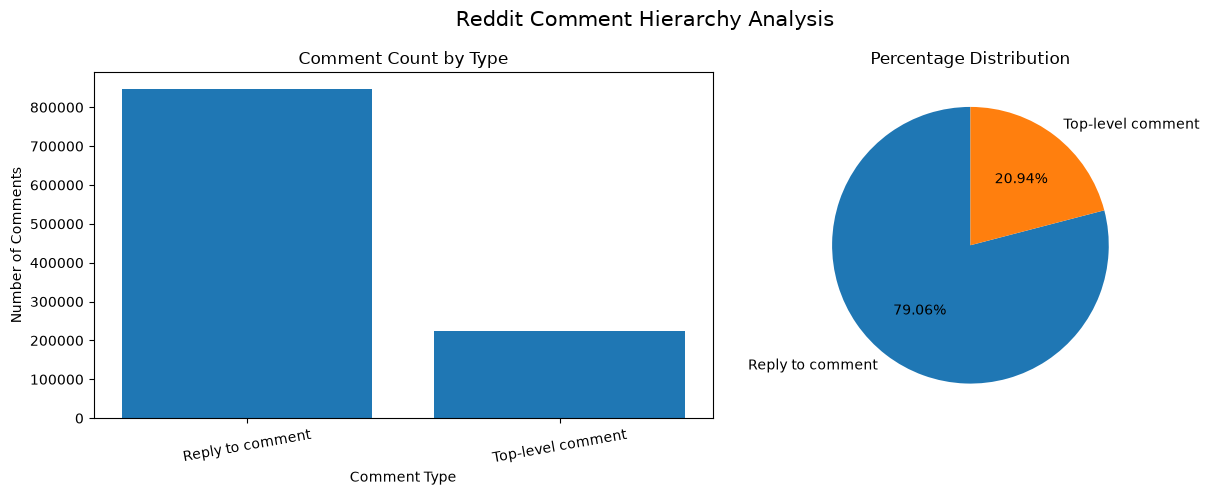

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(
    hierarchy_df["comment_level"],
    hierarchy_df["comment_count"]
)
axes[0].set_title("Comment Count by Type")
axes[0].set_xlabel("Comment Type")
axes[0].set_ylabel("Number of Comments")
axes[0].ticklabel_format(style="plain", axis="y")
axes[0].tick_params(axis="x", rotation=10)
axes[1].pie(
    hierarchy_df["comment_count"],
    labels=hierarchy_df["comment_level"],
    autopct="%1.2f%%",
    startangle=90
)
axes[1].set_title("Percentage Distribution")
fig.suptitle("Reddit Comment Hierarchy Analysis", fontsize=15)
plt.tight_layout()
fig.tight_layout()
save_path = OUTPUT_DIR / "comment_hierarchy.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
print("Saved:", save_path.resolve())
print("File exists:", save_path.exists())
plt.show()

In [16]:
print(f"---Extended Dataset Analysis---")
summary_query = f"""
    SELECT
        COUNT(*) AS total_comments,
        COUNT(DISTINCT id) AS unique_comments,
        COUNT(DISTINCT link_id) AS total_posts,
        COUNT(DISTINCT author) FILTER (WHERE author != '[deleted]') AS total_authors,
        MIN(TRY_CAST(created_utc AS BIGINT)) AS first_time,
        MAX(TRY_CAST(created_utc AS BIGINT)) AS last_time,
        ROUND(AVG(TRY_CAST(score AS DOUBLE)), 2) AS average_score
    FROM {CSV_SOURCE}
"""
summary_df = duckdb.sql(summary_query).df()
summary_df['first_date'] = pd.to_datetime(summary_df['first_time'], unit='s')
summary_df['last_date'] = pd.to_datetime(summary_df['last_time'], unit='s')
display(summary_df.drop(columns=['first_time', 'last_time']))
print(f"---Quality Summary---")
quality_query = f"""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (WHERE body IS NULL OR body = '') AS missing_bodies,
        COUNT(*) FILTER (WHERE author = '[deleted]') AS deleted_authors,
        COUNT(*) - COUNT(DISTINCT id) AS duplicate_rows
    FROM {CSV_SOURCE}
"""
quality_df = duckdb.sql(quality_query).df()
quality_df['deleted_percentage'] = np.round(quality_df['deleted_authors'] * 100 / quality_df['total_rows'], 2)
quality_df['duplicate_percentage'] = np.round(quality_df['duplicate_rows'] * 100 / quality_df['total_rows'], 2)
display(quality_df)

---Extended Dataset Analysis---


,total_comments,unique_comments,total_posts,total_authors,average_score,first_date,last_date
0,1071907,1070377,43354,125121,6.97,2006-05-01 00:01:03,2022-11-30 23:59:31


---Quality Summary---


,total_rows,missing_bodies,deleted_authors,duplicate_rows,deleted_percentage,duplicate_percentage
0,1071907,22,127743,1530,11.92,0.14


---Activity Analysis---


,month,comment_count,average_score,average_comments
0,2006-05-01 00:00:00+05:30,1715,2.77,1715.000000
1,2006-06-01 00:00:00+05:30,8,0.75,861.500000
2,2006-12-01 00:00:00+05:30,7822,3.23,3181.666667
3,2007-01-01 00:00:00+05:30,64,1.63,2402.250000
4,2007-07-01 00:00:00+05:30,17584,3.42,5438.600000


Saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\activity_analysis.png


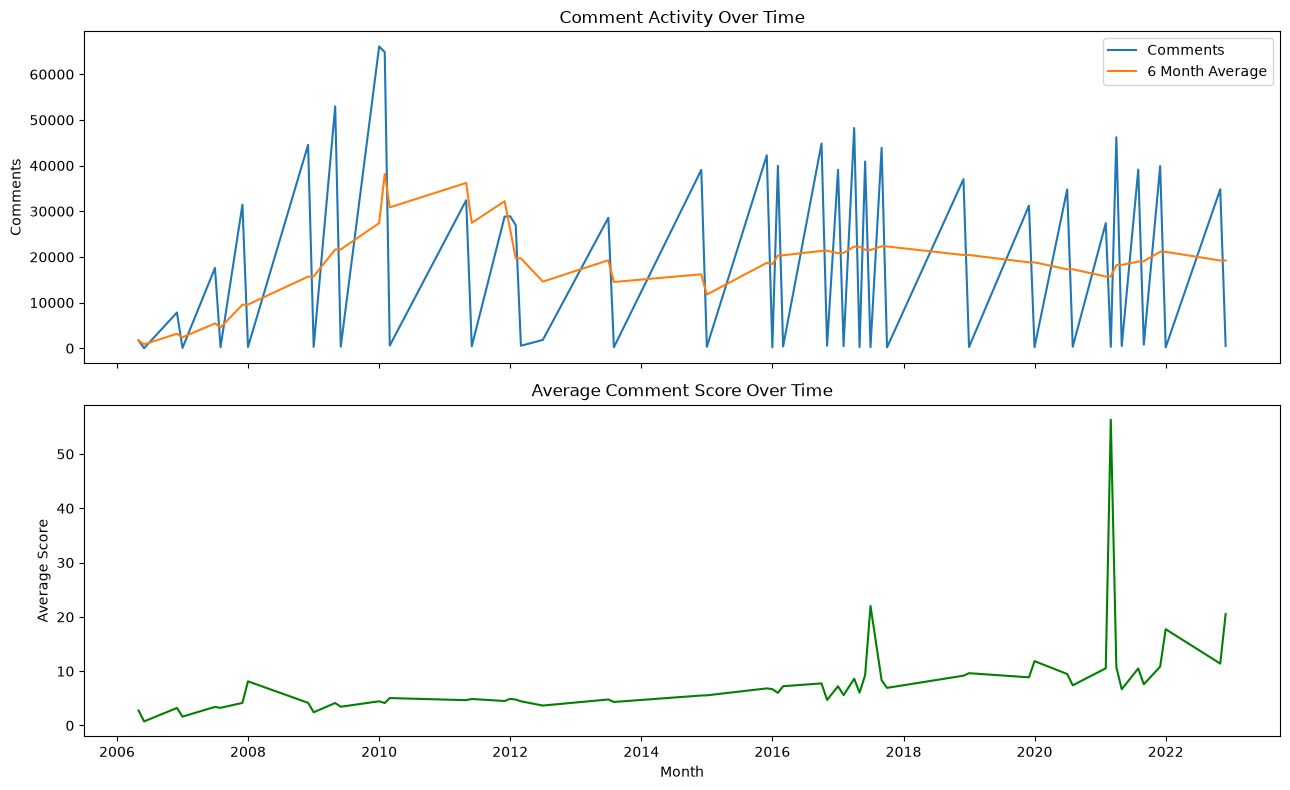

In [17]:
print(f"---Activity Analysis---")
activity_query = f"""
    SELECT
        DATE_TRUNC('month', TO_TIMESTAMP(TRY_CAST(created_utc AS BIGINT))) AS month,
        COUNT(*) AS comment_count,
        ROUND(AVG(TRY_CAST(score AS DOUBLE)), 2) AS average_score
    FROM reddit_comments
    WHERE TRY_CAST(created_utc AS BIGINT) IS NOT NULL
    GROUP BY 1
    ORDER BY 1
"""
activity_df = duckdb.sql(activity_query).df()
activity_df['month'] = pd.to_datetime(activity_df['month'])
activity_df['average_comments'] = activity_df['comment_count'].rolling(6, min_periods=1).mean()
display(activity_df.head())
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(activity_df['month'], activity_df['comment_count'], label='Comments')
axes[0].plot(activity_df['month'], activity_df['average_comments'], label='6 Month Average')
axes[0].set_title('Comment Activity Over Time')
axes[0].set_ylabel('Comments')
axes[0].legend()
axes[1].plot(activity_df['month'], activity_df['average_score'], color='green')
axes[1].set_title('Average Comment Score Over Time')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Score')
plt.tight_layout()
activity_path = OUTPUT_DIR / 'activity_analysis.png'
fig.savefig(activity_path, dpi=300, bbox_inches='tight')
print('Saved:', activity_path)
plt.show()

---Engagement and Author Analysis---


,comment_type,comment_count,average_score,total_gilded
0,Reply to comment,847486,5.97,209.0
1,Top-level comment,224421,10.75,183.0


,author,comment_count,post_count,average_score
0,grauenwolf,6595,1384,3.84
1,combinatorylogic,3299,418,1.91
2,s73v3r,2618,377,2.89
3,masklinn,2334,832,6.22
4,shevegen,2310,1129,0.95
5,yogthos,2247,397,3.27
6,MarshallBanana,2055,593,5.44
7,G_Morgan,1967,784,5.23
8,XANi_,1898,547,7.98
9,myringotomy,1720,482,2.69


Saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\engagement_and_authors.png


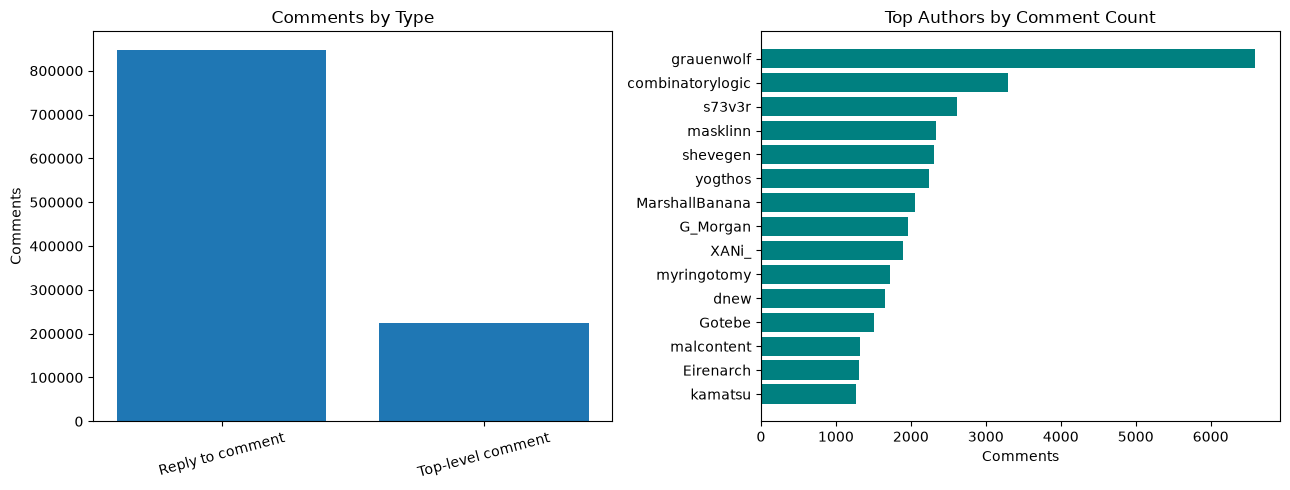

In [18]:
print(f"---Engagement and Author Analysis---")
engagement_query = f"""
    SELECT
        CASE
            WHEN starts_with(parent_id, 't1_') THEN 'Reply to comment'
            WHEN starts_with(parent_id, 't3_') THEN 'Top-level comment'
            ELSE 'Other'
        END AS comment_type,
        COUNT(*) AS comment_count,
        ROUND(AVG(TRY_CAST(score AS DOUBLE)), 2) AS average_score,
        SUM(COALESCE(TRY_CAST(gilded AS DOUBLE), 0)) AS total_gilded
    FROM reddit_comments
    GROUP BY 1
    ORDER BY comment_count DESC
"""
engagement_df = duckdb.sql(engagement_query).df()
display(engagement_df)
author_query = f"""
    SELECT author, COUNT(*) AS comment_count,
           COUNT(DISTINCT link_id) AS post_count,
           ROUND(AVG(TRY_CAST(score AS DOUBLE)), 2) AS average_score
    FROM reddit_comments
    WHERE author IS NOT NULL AND author != '[deleted]'
    GROUP BY author
    ORDER BY comment_count DESC
    LIMIT 15
"""
author_df = duckdb.sql(author_query).df()
display(author_df)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(engagement_df['comment_type'], engagement_df['comment_count'])
axes[0].set_title('Comments by Type')
axes[0].set_ylabel('Comments')
axes[0].tick_params(axis='x', rotation=15)
author_plot = author_df.sort_values('comment_count')
axes[1].barh(author_plot['author'], author_plot['comment_count'], color='teal')
axes[1].set_title('Top Authors by Comment Count')
axes[1].set_xlabel('Comments')
plt.tight_layout()
engagement_path = OUTPUT_DIR / 'engagement_and_authors.png'
fig.savefig(engagement_path, dpi=300, bbox_inches='tight')
print('Saved:', engagement_path)
plt.show()

---Comment Text Analysis---


,word,frequency
6,they,23872
16,it's,22825
41,your,19082
4,what,18615
145,all,16631
269,about,16267
111,more,16214
422,don't,16060
30,would,14451
58,code,14345


Saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\common_words.png


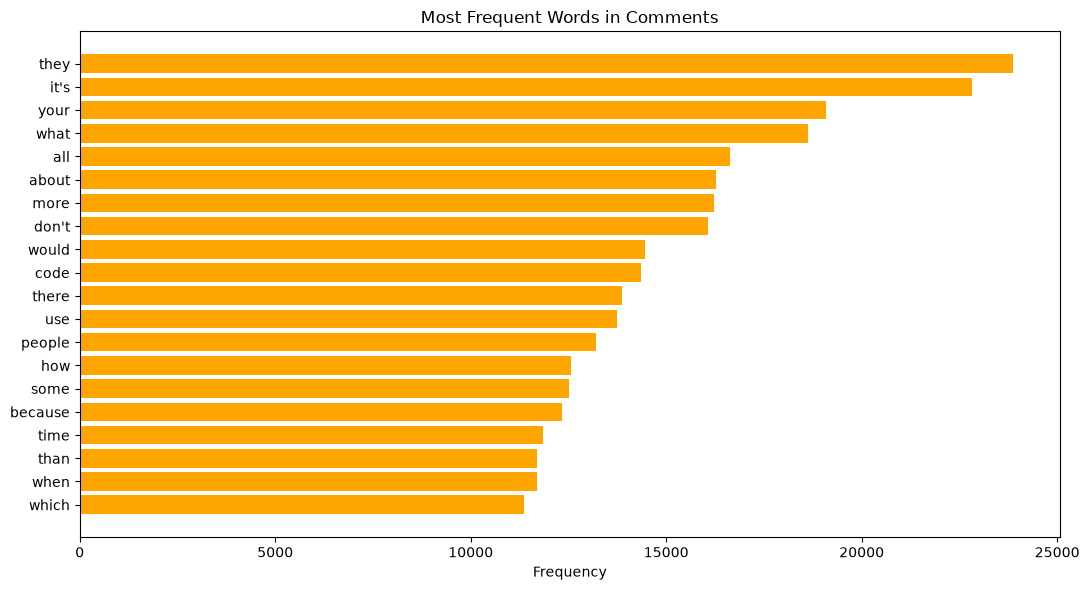

---Final Summary---
Comments analyzed: 1,071,907
Posts analyzed: 43,354
Authors analyzed: 125,121
Date range: 2006-05-01 to 2022-11-30


In [19]:
print(f"---Comment Text Analysis---")
text_query = f"""
    SELECT body
    FROM reddit_comments
    WHERE body IS NOT NULL AND body != '[deleted]'
    LIMIT 100000
"""
text_df = duckdb.sql(text_query).df()
common_words = {'the', 'and', 'that', 'this', 'with', 'from', 'have', 'for', 'you', 'are', 'was', 'but', 'not', 'can', 'one', 'just', 'like', 'http', 'https', 'www'}
word_count = {}
for comment_text in text_df['body'].astype(str):
    words = re.findall(r"[A-Za-z][A-Za-z']{2,}", comment_text.lower())
    for word in words:
        if word not in common_words:
            word_count[word] = word_count.get(word, 0) + 1
words_df = pd.DataFrame(list(word_count.items()), columns=['word', 'frequency'])
words_df = words_df.sort_values('frequency', ascending=False).head(20)
display(words_df)
fig, ax = plt.subplots(figsize=(11, 6))
words_plot = words_df.sort_values('frequency')
ax.barh(words_plot['word'], words_plot['frequency'], color='orange')
ax.set_title('Most Frequent Words in Comments')
ax.set_xlabel('Frequency')
plt.tight_layout()
words_path = OUTPUT_DIR / 'common_words.png'
fig.savefig(words_path, dpi=300, bbox_inches='tight')
print('Saved:', words_path)
plt.show()
print(f"---Final Summary---")
print(f"Comments analyzed: {int(summary_df.loc[0, 'total_comments']):,}")
print(f"Posts analyzed: {int(summary_df.loc[0, 'total_posts']):,}")
print(f"Authors analyzed: {int(summary_df.loc[0, 'total_authors']):,}")
print(f"Date range: {summary_df.loc[0, 'first_date'].date()} to {summary_df.loc[0, 'last_date'].date()}")

---Most Active Discussions---


,link_id,comment_count,author_count,average_score
0,t3_mzn4ji,4650,1352,5.87
1,t3_raorbk,4293,1050,4.38
2,t3_ato9n,2860,1693,4.77
3,t3_6heysw,2248,997,13.06
4,t3_63zg6f,2228,773,9.02
5,t3_637m7q,2103,858,8.44
6,t3_pdjnfr,2095,871,12.23
7,t3_p4woi7,1883,620,7.47
8,t3_6k419t,1879,1091,24.44
9,t3_mtz0ir,1718,456,9.02


Saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\most_active_discussions.png


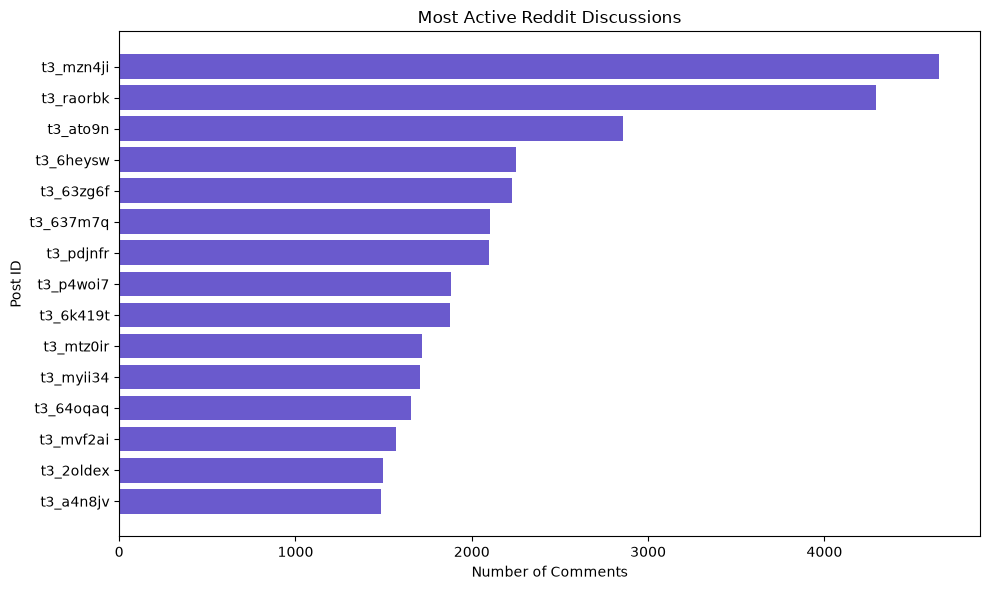

In [20]:
print(f"---Most Active Discussions---")
top_posts_query = """
    SELECT
        link_id,
        COUNT(*) AS comment_count,
        COUNT(DISTINCT author) FILTER (
            WHERE author IS NOT NULL AND author != '[deleted]'
        ) AS author_count,
        ROUND(AVG(TRY_CAST(score AS DOUBLE)), 2) AS average_score
    FROM reddit_comments
    GROUP BY link_id
    ORDER BY comment_count DESC
    LIMIT 15
"""
top_posts_df = duckdb.sql(top_posts_query).df()
display(top_posts_df)

fig, ax = plt.subplots(figsize=(10, 6))
post_plot = top_posts_df.sort_values("comment_count")
ax.barh(post_plot["link_id"], post_plot["comment_count"], color="slateblue")
ax.set_title("Most Active Reddit Discussions")
ax.set_xlabel("Number of Comments")
ax.set_ylabel("Post ID")
plt.tight_layout()
posts_path = OUTPUT_DIR / "most_active_discussions.png"
fig.savefig(posts_path, dpi=300, bbox_inches="tight")
print("Saved:", posts_path)
plt.show()


---Thread Depth and Branching Analysis---


,depth,comment_count
0,1,4
1,2,4
2,3,3
3,4,4
4,5,4
5,6,2
6,7,1


,parent_id,reply_count
0,t1_dfteepk,4
1,t1_dftzv08,3
4,t1_dfubdhf,2
5,t1_dfubvyo,2
2,t1_dfu0h92,1
3,t1_dfu5unv,1
6,t1_dfuep0i,1
7,t1_dfuf7sb,1
8,t1_dfui667,1
9,t1_dfuq6au,1


Maximum thread depth: 7
Average replies per replied-to comment: 1.64
Saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\thread_depth_and_branching.png


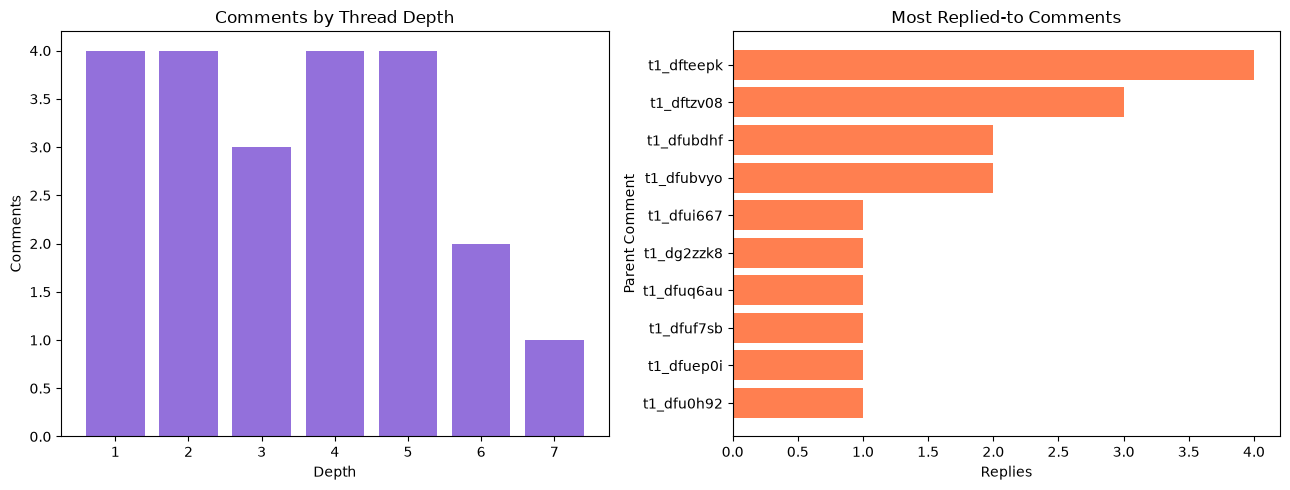

In [21]:
print(f"---Thread Depth and Branching Analysis---")
depth_summary = (
    df_tree.groupby("depth")
    .size()
    .reset_index(name="comment_count")
)
reply_counts = (
    df_tree[df_tree["parent_id"].str.startswith("t1_")]
    .groupby("parent_id")
    .size()
    .reset_index(name="reply_count")
)
display(depth_summary)
display(reply_counts.sort_values("reply_count", ascending=False).head(10))
print("Maximum thread depth:", int(df_tree["depth"].max()))
print("Average replies per replied-to comment:", round(reply_counts["reply_count"].mean(), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(depth_summary["depth"], depth_summary["comment_count"], color="mediumpurple")
axes[0].set_title("Comments by Thread Depth")
axes[0].set_xlabel("Depth")
axes[0].set_ylabel("Comments")
branch_plot = reply_counts.sort_values("reply_count").tail(10)
axes[1].barh(branch_plot["parent_id"], branch_plot["reply_count"], color="coral")
axes[1].set_title("Most Replied-to Comments")
axes[1].set_xlabel("Replies")
axes[1].set_ylabel("Parent Comment")
plt.tight_layout()
thread_path = OUTPUT_DIR / "thread_depth_and_branching.png"
fig.savefig(thread_path, dpi=300, bbox_inches="tight")
print("Saved:", thread_path)
plt.show()


---Final Dashboard---
Saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\project_dashboard.png


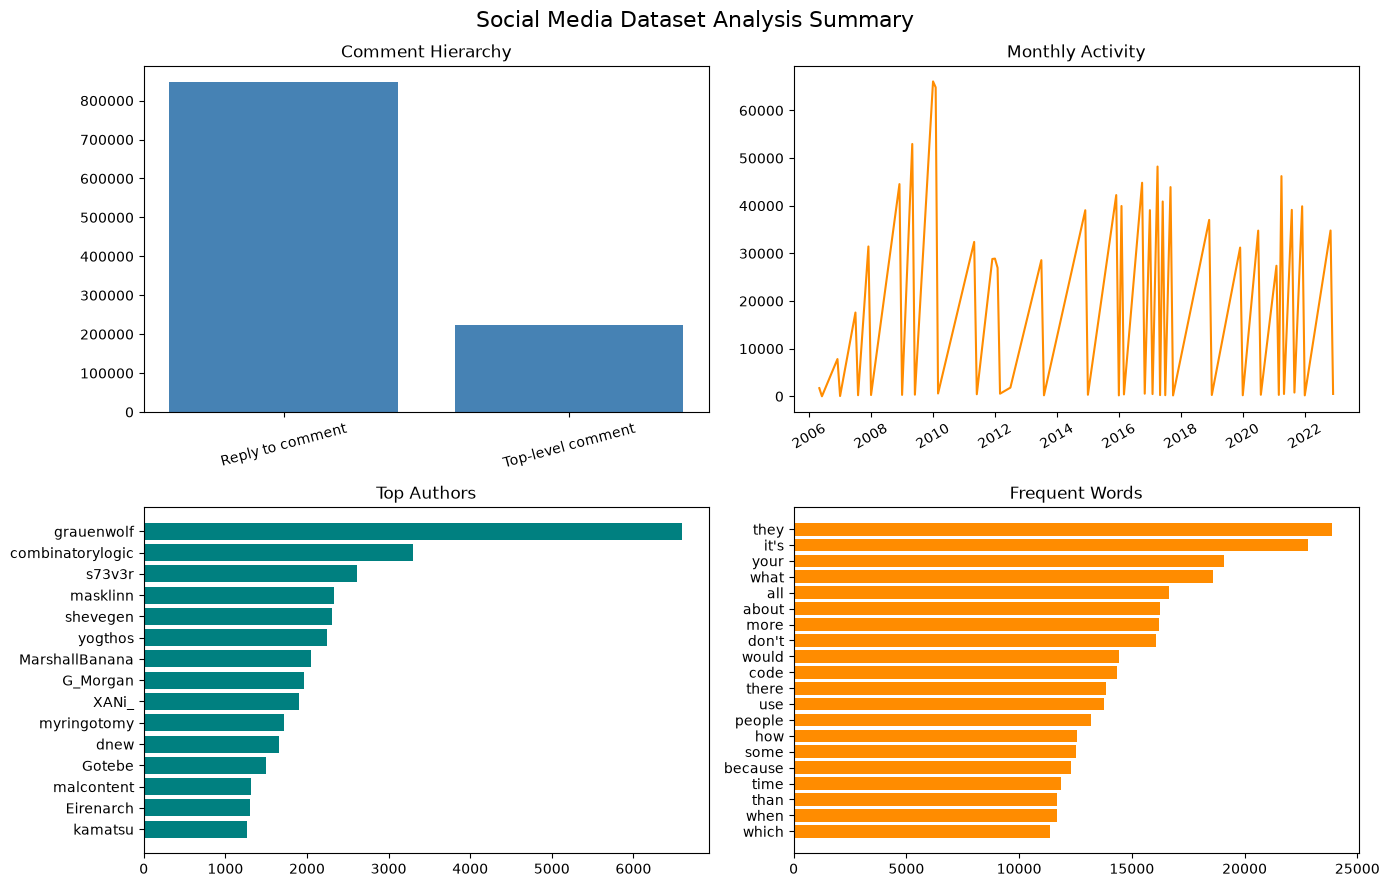

In [22]:
print(f"---Final Dashboard---")
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].bar(hierarchy_df["comment_level"], hierarchy_df["comment_count"], color="steelblue")
axes[0, 0].set_title("Comment Hierarchy")
axes[0, 0].tick_params(axis="x", rotation=15)
axes[0, 1].plot(activity_df["month"], activity_df["comment_count"], color="darkorange")
axes[0, 1].set_title("Monthly Activity")
axes[0, 1].tick_params(axis="x", rotation=30)
axes[1, 0].barh(author_plot["author"], author_plot["comment_count"], color="teal")
axes[1, 0].set_title("Top Authors")
axes[1, 1].barh(words_plot["word"], words_plot["frequency"], color="darkorange")
axes[1, 1].set_title("Frequent Words")
fig.suptitle("Social Media Dataset Analysis Summary", fontsize=16)
plt.tight_layout()
dashboard_path = OUTPUT_DIR / "project_dashboard.png"
fig.savefig(dashboard_path, dpi=300, bbox_inches="tight")
print("Saved:", dashboard_path)
plt.show()


## 5. Sentiment and Importance Analysis


In [23]:
print("--- Sentiment and Importance Analysis ---")
analyzer = SentimentIntensityAnalyzer()
tokenizer = TreebankWordTokenizer()
# Keep the updated sentiment/importance dataset separate from graph files.
SENTIMENT_OUTPUT_DIR = Path.cwd() / "outputs" / "sentiment_importance"
SENTIMENT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df = duckdb.sql("""
    SELECT
        id,
        link_id,
        parent_id,
        body,
        score,
        gilded,
        total_awards_received,
        controversiality,
        created_utc
    FROM reddit_comments
    WHERE body IS NOT NULL
      AND TRIM(body) != ''
      AND body NOT IN ('[deleted]', '[removed]')
""").df()
def get_sentiment(text):
    scores = analyzer.polarity_scores(str(text))
    if scores["compound"] >= 0.05:
        label = "Positive"
    elif scores["compound"] <= -0.05:
        label = "Negative"
    else:
        label = "Neutral"
    return pd.Series({
        "sentiment": label,
        "positive_score": scores["pos"],
        "negative_score": scores["neg"],
        "neutral_score": scores["neu"],
        "compound_score": scores["compound"]
    })
keywords = [
    "urgent", "critical", "important", "security",
    "warning", "emergency", "vulnerability",
    "outage", "failure", "crash"
]
def get_importance(row):
    text = str(row["body"]).lower()
    def safe_number(value):
        return 0 if pd.isna(value) else float(value)
    score = (
        max(safe_number(row["score"]), 0)
        + 2 * safe_number(row["gilded"])
        + 2 * safe_number(row["total_awards_received"])
        + 3 * safe_number(row["controversiality"])
    )
    keyword_matches = sum(
        1 for word in keywords
        if re.search(r"\b" + re.escape(word) + r"\b", text)
    )
    score += keyword_matches * 5
    if score >= 15:
        return "High"
    elif score >= 5:
        return "Medium"
    else:
        return "Low"
sentiment_df = df["body"].apply(get_sentiment)
df = pd.concat([df, sentiment_df], axis=1)
df["word_count"] = df["body"].apply(
    lambda x: len(tokenizer.tokenize(str(x)))
)
df["importance"] = df.apply(get_importance, axis=1)
output_path = SENTIMENT_OUTPUT_DIR / "reddit_sentiment_importance.csv"
df.to_csv(output_path, index=False)
print("\n--- Random Comment Samples ---")
display(
    df.sample(n=min(15, len(df)))[[
        "body",
        "sentiment",
        "compound_score",
        "importance"
    ]]
)
print("\n--- Analysis Completed ---")
print("Total comments:", len(df))
print("Saved to:", output_path)


--- Sentiment and Importance Analysis ---

--- Random Comment Samples ---


,body,sentiment,compound_score,importance
633142,But really is kicking ass at datastructure/alg...,Negative,-0.6460,Medium
8357,The uPlay game overlay messaging has this exac...,Positive,0.4404,High
628614,I literally snorted in front of my ethics lect...,Positive,0.4404,High
615749,&gt; I work as lead programmer at a small shop...,Negative,-0.4023,Low
522019,Hey Guys here is some more detailed info:\n\n ...,Positive,0.9375,Low
278794,"In other words, *staging your commit*?",Positive,0.2960,Low
203633,"I dunno, I\\\\\\\\\\\\\\\\\\\\\\\'d say he mig...",Neutral,0.0000,Medium
347801,"In some sense, the 3rd was the easiest because...",Positive,0.8039,Low
983369,Yes let us discuss this topic in immense detai...,Positive,0.4019,Medium
646746,I like the glade approach too. Although genera...,Positive,0.7311,Low



--- Analysis Completed ---
Total comments: 1002084
Saved to: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\sentiment_importance\reddit_sentiment_importance.csv


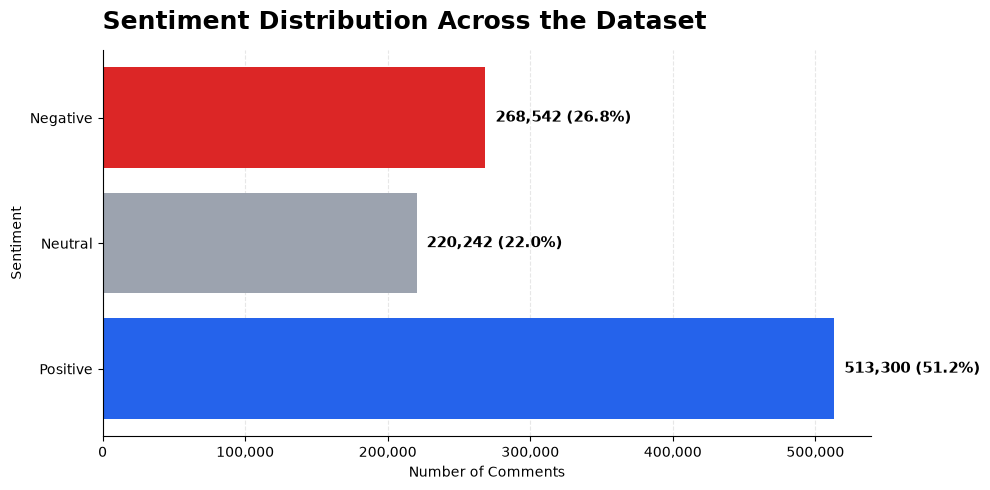

Figure saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\sentiment_distribution_bar_chart.png


In [28]:
sentiment_order = ["Positive", "Neutral", "Negative"]
sentiment_colors = {
    "Positive": "#2563EB",
    "Neutral": "#9CA3AF",
    "Negative": "#DC2626"
}
sentiment_counts = (
    df["sentiment"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)
sentiment_percent = sentiment_counts.div(
    sentiment_counts.sum()
).mul(100)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(
    sentiment_order,
    sentiment_counts.values,
    color=[sentiment_colors[item] for item in sentiment_order]
)
for bar, count, percentage in zip(
    bars,
    sentiment_counts.values,
    sentiment_percent.values
):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  {count:,} ({percentage:.1f}%)",
        va="center",
        fontsize=11,
        fontweight="bold"
    )
ax.set_title(
    "Sentiment Distribution Across the Dataset",
    fontsize=18,
    fontweight="bold",
    loc="left",
    pad=15
)
ax.set_xlabel("Number of Comments")
ax.set_ylabel("Sentiment")
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}")
)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
sns.despine()
plt.tight_layout()
sentiment_path = OUTPUT_DIR / "sentiment_distribution_bar_chart.png"
plt.savefig(
    sentiment_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
print("Figure saved:", sentiment_path)


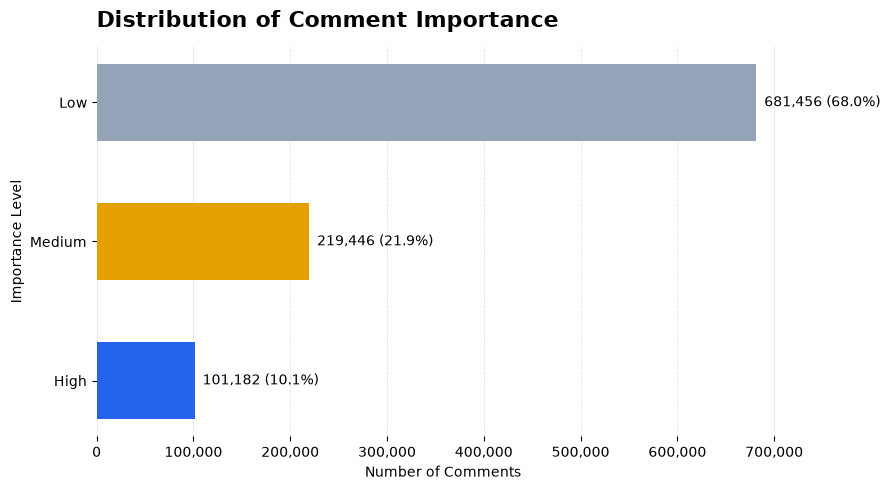

Figure saved: C:\Users\Medam Hexnebyek\Desktop\AnalysisAndVisualizationOfSocialMediaData\outputs\figures\importance_distribution_bar_chart.png


In [31]:
importance_order = ["Low", "Medium", "High"]
importance_colors = {
    "Low": "#94A3B8",
    "Medium": "#E5A000",
    "High": "#2563EB"
}
importance_counts = (
    df["importance"]
    .value_counts()
    .reindex(importance_order, fill_value=0)
)
importance_percent = (
    importance_counts / importance_counts.sum() * 100
)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(
    importance_order,
    importance_counts.values,
    color=[importance_colors[level] for level in importance_order],
    height=0.55
)
for bar, count, percentage in zip(
    bars,
    importance_counts.values,
    importance_percent.values
):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"  {count:,} ({percentage:.1f}%)",
        va="center",
        fontsize=10
    )
ax.set_title(
    "Distribution of Comment Importance",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=14
)
ax.set_xlabel("Number of Comments")
ax.set_ylabel("Importance Level")
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value:,.0f}")
)
ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)
ax.set_axisbelow(True)
ax.invert_yaxis()
sns.despine(left=True, bottom=True)
plt.tight_layout()
importance_path = OUTPUT_DIR / "importance_distribution_bar_chart.png"
plt.savefig(
    importance_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()
print("Figure saved:", importance_path)
